# Technical Report: Replicating "Genes Mirror Geography" with (AADR v66) dataset
## Computational Replication, Reference Sensitivity & Supervised Localization Limits

**Question.** Do the leading components of modern human genotype variation reproduce a recognizable geographic arrangement without using a map as a PCA target?

We analyze 996 individuals at 46,213 LD-pruned markers, fit a fixed 428-person reference, and project the whole cohort. A single similarity transform orients PC1/PC2 to regional locality centroids. The aligned axes correlate with longitude and latitude at approximately 0.861 and 0.881. Together the first two PCs explain 0.959% of reference variation. These descriptive associations show spatial structure; the point cloud does not reconstruct a shoreline or establish an individual's birthplace.

Reference sensitivity qualifies the correspondence. Exploratory supervised experiments examine a separate question—predicting known localities—and help explain why the final presentation retains the two-PC geometry.

For derivations, small numerical examples and a code walkthrough, use the [maths-and-code companion](genes_mirror_geography_math_code.ipynb). This report starts from the current study dataset and concentrates on evidence and interpretation.

### Reproducibility

Run the cells in order from inside this project. The local AADR `.geno`, `.ind`, `.snp` and `.anno` inputs are required; several GB of RAM are useful. Later real-data cells also write scratch tables, figures, and detailed logs to `results/notebook/`, the setup cell only creates those folders.

In [1]:
from pathlib import Path
from contextlib import redirect_stdout
import io, sys, json, importlib, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown, HTML
from sklearn.decomposition import PCA

here = Path.cwd().resolve()
project = next(p for p in [here, *here.parents]
               if (p / "research/pipeline/run_human_origins_pca.py").exists())
research = project / "research"
sys.path.insert(0, str(research / "pipeline"))
import run_human_origins_pca as pipeline
importlib.reload(pipeline)

WORK = research / "results" / "notebook"
for attribute, folder in [("PROCESSED", "processed"), ("QC_DIR", "qc"),
                          ("STATS", "stats"), ("PLOTS", "plots"), ("WEBSITE_DATA", "atlas")]:
    directory = WORK / folder
    directory.mkdir(parents=True, exist_ok=True)
    setattr(pipeline, attribute, directory)
(WORK / "execution_details.txt").write_text("")
def run_step(function, *args):
    """Keep detailed processing logs on disk and show selected outputs below."""
    stream = io.StringIO()
    try:
        with redirect_stdout(stream):
            value = function(*args)
    finally:
        with (WORK / "execution_details.txt").open("a") as log:
            log.write(stream.getvalue())
    return value

def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
protected = [p for p in (project / "website").rglob("*") if p.is_file()]
protected += list((research / "pipeline").glob("*.py"))
protected += [p for d in ["results/stats", "results/plots"] for p in (research/d).glob("*")
              if p.is_file() and p.name != "notebook_execution.log"]
protected_hashes = {str(p.relative_to(project)): digest(p) for p in protected}
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "#fafcfb",
                     "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
region_colors = {"Northern & Nordic": "#00836f", "Western & Atlantic": "#2467ad",
                 "Iberia & Basque": "#bf4f55", "Mediterranean": "#a96318",
                 "Balkans & Southeast": "#477d44", "Central & Eastern": "#7753ba"}
region_handles = [Line2D([], [], marker="o", linestyle="", color=c, label=r)
                  for r,c in region_colors.items()]
def colors_for(frame):
    return [region_colors[pipeline.get_region_and_color(p)[0]] for p in frame.population]
def save_figure(fig, name):
    fig.savefig(pipeline.PLOTS / name, dpi=170, bbox_inches="tight")
    plt.show()
    plt.close(fig)
def read_js_data(path):
    return json.loads(Path(path).read_text().split("=", 1)[1].strip().rstrip(";"))
def haversine_km(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.asarray, [lon1, lat1, lon2, lat2])
    a = np.sin(np.radians(lat2-lat1)/2)**2 + np.cos(np.radians(lat1))*np.cos(np.radians(lat2))*np.sin(np.radians(lon2-lon1)/2)**2
    return 2*6371*np.arcsin(np.sqrt(np.clip(a, 0, 1)))

run_step(pipeline.chunk_1_verify_environment)
print("Inputs verified. Run the remaining cells to see tables and figures inline.")
print("Scratch files and processing logs, created by later cells:", WORK.relative_to(project))

Inputs verified. Run the remaining cells to see tables and figures inline.
Scratch files and processing logs, created by later cells: research/results/notebook


## 1. Data and study design


The analysis uses **996 modern individuals, 52 regional groups and 26 country labels** from the local AADR v66 Human Origins-compatible release. The **428-person PCA reference** and the **407-person core marker-QC panel** have different roles: the former defines the genetic axes; the latter determines call-rate, allele-frequency and LD filters.

Selection requires an explicit numeric date of zero, the predefined European population/platform scope, and one record per individual ID, preferring `.HO` and then higher coverage. The existing publication, population and six-ID relatedness exclusions remain part of the design; their rationale and relatedness estimates are not independently revalidated here. The reference uses fixed group quotas, so it is not a representative random sample. Full details are in [the selection implementation](pipeline/run_human_origins_pca.py) and [reference membership](pipeline/cohort_reference.json).

Locations are annotation localities or labeled proxies, including the assigned Tuscany location. They are not verified individual birthplaces. Country and regional labels annotate the figures after PCA; coordinates do not enter the PCA fit.

### At aglance comparison

| Parameter | Novembre et al. (2008) | This replication (AADR v66) |
|---|---|---|
| Sample size (N) | 1,387 Europeans in the final POPRES analysis | 996 modern European records (date = 0; 672 .HO and 324 .DG) |
| Genotyping platform | Affymetrix 500K; 500,568 assayed loci | Human Origins-compatible data; 276,725-marker input manifest |
| Post-QC / LD-pruned SNPs (M) | 197,146 | 46,213; core-panel MAF ≥ 0.05 and sliding-window r² threshold 0.20 |
| Explained variance (PC1 + PC2) | Approximately 0.45% (0.30% + 0.15%) | 0.959% (0.580% + 0.379%) of reference-panel variance |
| Alignment of the displayed PCA | 16° counterclockwise rotation selected by geographic correlations (Figure 1) | One orthogonal Procrustes similarity transform: Q, one scale s, and translation; 52 equally weighted calibration centroids |

Source: Novembre et al. (2008), *Genes mirror geography within Europe*, Nature 456:98–101, especially Figure 1 and Methods. The original paper's geographic assignment uses separate regression models with quadratic and interaction terms; those are distinct from its PCA display rotation. Cohorts, marker sets and preprocessing differ, so the variance percentages are not comparable measures of geographic prediction accuracy.


In [2]:
cohort = run_step(pipeline.chunk_2_cohort_selection)

assert len(cohort) == 996 and cohort.sample_id.is_unique
display(pd.Series({
    "Individuals": len(cohort), "Regional groups": cohort.population.nunique(),
    "Country labels": cohort.country.nunique(),
    "PCA reference individuals": int(cohort.is_pca_reference.sum()),
    "Marker-QC panel individuals": int(cohort.is_core_ho.sum())
}, name="Study design").to_frame())

display(cohort.groupby("coordinate_source").size().rename("Individuals").to_frame())

,Study design
Individuals,996
Regional groups,52
Country labels,26
PCA reference individuals,428
Marker-QC panel individuals,407


,Individuals
coordinate_source,
AADR annotation,775
Assigned Tuscany proxy,107
Assigned locality proxy,114


## 2. Genotypes and marker quality control

The sample-major TGENO file stores four two-bit calls per byte after a 48-byte header. Codes 0, 1 and 2 denote allele dosage; 3 denotes missing. The decoder checks the header, dimensions and file length. An observed excerpt follows.

We retain autosomes outside seven predefined high-LD intervals, then require complete calls and minor allele frequency at least 5% in the core QC panel. All retained individuals meet a 95% call-rate threshold across eligible autosomal markers. Greedy LD pruning operates within each chromosome, using 50-marker windows, five-marker steps and squared correlation above 0.20 as the exclusion threshold. These stringent, inherited rules define this analysis; retained markers are not thereby guaranteed independent.

**Measured call used in the atlas zoom.** The SVG-to-Canvas handoff uses the first column of the atlas’s displayed retained-marker window:

| Individual | rs2494432 · chromosome 1, position 2,349,769 · counted allele G |
|---|---|
| MOL-005.HO | GG → dosage 2 |

The call was checked against the raw TGENO byte, SNP manifest and retained-marker index. The atlas window uses 24 selected retained markers, rather than the first 24 columns of the full matrix. Its readable twelve-row excerpt expands to all 996 decoded rows. Flanking animation letters and parental roles are schematic; the genotype calls are unphased. Counting the first listed SNP allele follows the [EIGENSOFT format documentation](https://github.com/DReichLab/EIG/blob/master/CONVERTF/README).


In [3]:
snp_manifest, eligible_snps = run_step(pipeline.chunk_3_snp_manifest_and_inversion_qc)
G_all = run_step(pipeline.chunk_4_binary_genotype_extraction, cohort, snp_manifest, eligible_snps)

assert np.isin(G_all[np.isfinite(G_all)], [0, 1, 2]).all()
display(pd.DataFrame(G_all[:5, :8], index=cohort.sample_id.iloc[:5],
                     columns=eligible_snps.snpid.iloc[:8]))


print("Observed dosage matrix:", G_all.shape, "— rows are people; columns are markers.")

Observed dosage matrix: (996, 273738) — rows are people; columns are markers.


snpid,rs7419119,rs13302957,rs9442372,rs147606383,rs4970405,rs1320571,rs3813199,rs61559999
sample_id,,,,,,,,
MOL-005.HO,2.0,1.0,0.0,2.0,2.0,2.0,2.0,1.0
MOL-008.HO,2.0,2.0,0.0,2.0,2.0,2.0,2.0,2.0
MOL-015.HO,2.0,0.0,1.0,2.0,2.0,2.0,2.0,2.0
MOL-024.HO,2.0,1.0,0.0,1.0,2.0,2.0,2.0,2.0
MOL-058.HO,2.0,0.0,1.0,1.0,2.0,2.0,2.0,2.0


In [4]:
core = cohort.is_core_ho.to_numpy()

complete_core = np.isfinite(G_all[core]).all(axis=0)

G_maf, snp_qc = run_step(pipeline.chunk_5_quality_control, G_all, eligible_snps, cohort)

qc_counts = {"Array markers": len(snp_manifest),
             "Eligible autosomal markers": G_all.shape[1],
             "Complete calls in the QC panel": int(complete_core.sum()),
             "MAF at least 5% in that panel": G_maf.shape[1]}
del G_all
G_pruned, retained_snps = run_step(pipeline.chunk_6_ld_pruning, G_maf, snp_qc, cohort)
del G_maf
assert G_pruned.shape == (996, 46213)

qc_counts["After chromosome-local LD pruning"] = G_pruned.shape[1]

display(pd.Series(qc_counts, name="Markers").to_frame())

print("Minimum individual call rate:", round(float(cohort.autosomal_call_rate.min()), 5))

Minimum individual call rate: 0.95691


,Markers
Array markers,276725
Eligible autosomal markers,273738
Complete calls in the QC panel,164190
MAF at least 5% in that panel,84118
After chromosome-local LD pruning,46213


## 3. Reference normalization and principal components

For person $i$ and marker $j$, let $G_{ij}$ be allele dosage and $p_j$ the allele frequency estimated in the PCA reference:

$$Z_{ij}=\frac{G_{ij}-2p_j}{\sqrt{2p_j(1-p_j)}}.$$

Missing values are mean-imputed, giving $Z_{ij}=0$; near-zero denominators are guarded. PCA centers the normalized reference matrix and obtains orthonormal feature directions $V$. Every person's scores are $(Z_i-\mu_{\mathrm{ref}})V_{10}$. No locality coordinates enter this fit. The implementation below exposes the normalization, fitting and projection rather than hiding them inside a pipeline call. PCA centering and component conventions follow [scikit-learn's documentation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

In [5]:
reference_mask = cohort.is_pca_reference.to_numpy()

G_reference = G_pruned[reference_mask]

p = np.nanmean(G_reference, axis=0) / 2

denominator = np.sqrt(2*p*(1-p))

denominator[denominator < 1e-6] = 1

Z_reference = np.nan_to_num((G_reference - 2*p) / denominator, nan=0.0)
Z_all = np.nan_to_num((G_pruned - 2*p) / denominator, nan=0.0)

model = PCA(n_components=10, random_state=42)
model.fit(Z_reference)

scores = model.transform(Z_all)
variance_pct = model.explained_variance_ratio_ * 100

results = cohort.copy()

for k in range(10):
    results[f"PC{k+1}"] = scores[:, k].astype(float)

np.testing.assert_allclose(
    (Z_all[:5] - model.mean_) @ model.components_.T,
    scores[:5], atol=2e-5, rtol=2e-5)


print("Reference matrix:", Z_reference.shape, "| projected scores:", scores.shape)

display(pd.DataFrame({"PC": np.arange(1, 11), "Reference variance (%)": variance_pct}).round(4))

Reference matrix: (428, 46213) | projected scores: (996, 10)


,PC,Reference variance (%)
0,1,0.5797
1,2,0.3789
2,3,0.2803
3,4,0.2772
4,5,0.2707
5,6,0.2689
6,7,0.2677
7,8,0.2669
8,9,0.2658
9,10,0.2647


The first two PCs explain 0.9586% of reference variation.


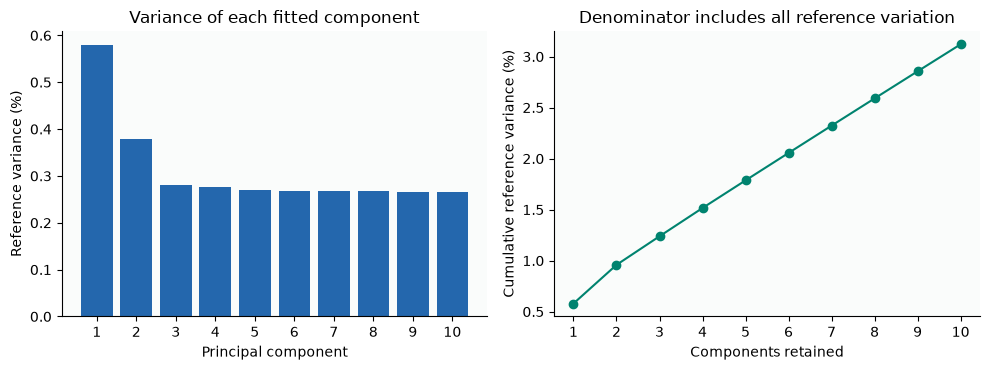

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].bar(np.arange(1, 11), variance_pct, color="#2467ad")
axes[0].set(xlabel="Principal component", ylabel="Reference variance (%)",
            title="Variance of each fitted component", xticks=np.arange(1, 11))
axes[1].plot(np.arange(1, 11), variance_pct.cumsum(), "o-", color="#00836f")
axes[1].set(xlabel="Components retained", ylabel="Cumulative reference variance (%)",
            title="Denominator includes all reference variation", xticks=np.arange(1, 11))
fig.tight_layout()
save_figure(fig, "01_reference_variance.png")
print(f"The first two PCs explain {variance_pct[:2].sum():.4f}% of reference variation.")

## 4. One global geographic alignment

Alignment uses equally weighted means of all 52 regional groups in the predefined calibration subset. Let $A$ contain their PC1/PC2 means. Locality means form $B=(\mathrm{longitude}\cos\phi_0,\mathrm{latitude})$, where $\phi_0$ is the mean centroid latitude.

For centered matrices $A_c,B_c$, compute $A_c^\top B_c=U\Sigma V^\top$, then

$$Q=UV^\top,\qquad s=\frac{\operatorname{tr}\Sigma}{\|A_c\|_F^2},
\qquad F(P)=s(P-\bar A)Q+\bar B.$$

$Q$ permits a sign reflection, consistent with arbitrary PC signs. One common scale preserves all ratios of planar pair distances. Geography is used here to orient and calibrate the display, so the overall experiment is not geography-blind. No independent axis stretch, per-country adjustment, jitter or coastline constraint positions the dots.

In [7]:
# Use the predefined calibration membership, with equal weight per regional group.
calibration = results.loc[results.in_legacy_cohort]
centroids = calibration.groupby("population")[["PC1", "PC2", "longitude", "latitude"]].mean()
A = centroids[["PC1", "PC2"]].to_numpy(dtype=float)

phi0 = float(centroids.latitude.mean())
longitude_factor = float(np.cos(np.radians(phi0)))

B = centroids[["longitude", "latitude"]].to_numpy() * [longitude_factor, 1]

a_mean, b_mean = A.mean(0), B.mean(0)
Ac, Bc = A-a_mean, B-b_mean

U_align, singular_align, Vt_align = np.linalg.svd(Ac.T @ Bc)
Q = U_align @ Vt_align

scale = float(singular_align.sum() / np.square(Ac).sum())
aligned = (results[["PC1", "PC2"]].to_numpy() - a_mean) @ Q * scale + b_mean

results[["RotEW", "RotNS"]] = aligned
results[["rotLon", "rotLat"]] = aligned / [longitude_factor, 1]

disparity = float(np.square(Ac @ Q * scale + b_mean - B).sum() / np.square(Bc).sum())

alignment = {"reference_latitude": phi0, "longitude_factor": longitude_factor,
             "scale": scale, "rotation": Q.tolist(), "pc_center": a_mean.tolist(),
             "planar_center": b_mean.tolist(), "disparity": disparity}

np.testing.assert_allclose(Q.T @ Q, np.eye(2), atol=1e-12)


# A similarity transform multiplies every planar pair distance by the same scale.
pair_index = np.array([[0, 100], [25, 250], [400, 700], [800, 995]])
raw_xy = results[["PC1", "PC2"]].to_numpy()
d_before = np.linalg.norm(raw_xy[pair_index[:, 0]] - raw_xy[pair_index[:, 1]], axis=1)
d_after = np.linalg.norm(aligned[pair_index[:, 0]] - aligned[pair_index[:, 1]], axis=1)
np.testing.assert_allclose(d_after, scale*d_before, atol=1e-10)
display(pd.Series({"Calibration groups": len(centroids), "Reference latitude (degrees)": phi0,
                   "Common scale": scale, "det(Q)": np.linalg.det(Q),
                   "Normalized centroid residual": disparity}, name="Alignment").to_frame())

,Alignment
Calibration groups,52.000000
Reference latitude (degrees),47.050591
Common scale,0.578776
det(Q),1.000000
Normalized centroid residual,0.194905


## 5. Geographic correspondence

The first panel shows genetic coordinates; the second applies the single transform; the third shows locality metadata. The latter two share limits and equal planar aspect. Colors are regional annotations applied after PCA. No map outlines are drawn.

Reported correlations are descriptive, after fitted alignment. They are not percentages of people located correctly, held-out prediction accuracy, or correlations between all pairwise genetic and geographic distances.

,Comparison,Longitude r,Latitude r
0,Individuals,0.8615,0.8813
1,Regional means,0.9166,0.9002


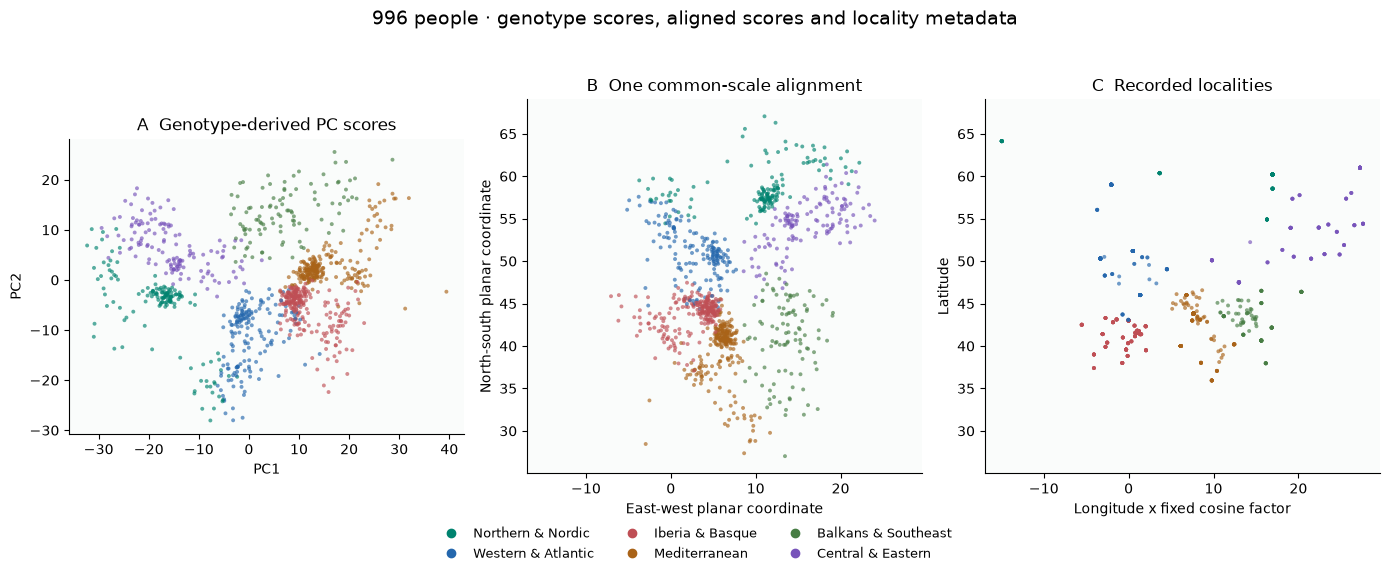

In [8]:
metrics = pipeline.descriptive_metrics(results)
metrics.update(snps_analyzed=G_pruned.shape[1], reference_size=int(reference_mask.sum()))
summary = pd.DataFrame({
    "Comparison": ["Individuals", "Regional means"],
    "Longitude r": [metrics["r_EastWest_Longitude"], metrics["r_centroid_EastWest"]],
    "Latitude r": [metrics["r_NorthSouth_Latitude"], metrics["r_centroid_NorthSouth"]]
})
display(summary.round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 5.7))
panels = [(raw_xy, "A  Genotype-derived PC scores", "PC1", "PC2"),
          (aligned, "B  One common-scale alignment", "East-west planar coordinate", "North-south planar coordinate"),
          (results[["longitude", "latitude"]].to_numpy()*[longitude_factor, 1],
           "C  Recorded localities", "Longitude x fixed cosine factor", "Latitude")]

for ax, (xy, title, xlabel, ylabel) in zip(axes, panels):
    ax.scatter(*xy.T, s=8, c=colors_for(results), alpha=.65, linewidths=0)
    ax.set_aspect("equal", adjustable="box")
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)

comparison_xy = np.vstack([panels[1][0], panels[2][0]])
low, high = comparison_xy.min(0)-2, comparison_xy.max(0)+2

for ax in axes[1:]:
    ax.set_xlim(low[0], high[0]); ax.set_ylim(low[1], high[1])
fig.legend(handles=region_handles, loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.suptitle("996 people · genotype scores, aligned scores and locality metadata", fontsize=14)
fig.tight_layout(rect=(0, .12, 1, .93))

save_figure(fig, "02_genetic_and_geographic_positions.png")

### Interactive inspection

Hover to inspect individuals. The optional Europe outline starts off and uses the same geographic projection as the points; toggling it never changes their positions.

In [9]:
import plotly.graph_objects as go


plot = go.Figure()
map_x, map_y = [], []

geo = json.loads((pipeline.RAW/"europe.geojson").read_text())


for feature in geo["features"]:
    geometry = feature["geometry"]
    polygons = [geometry["coordinates"]] if geometry["type"] == "Polygon" else geometry["coordinates"]
    for polygon in polygons:
        for ring in polygon:
            for lon, lat, *_ in ring:
                if -28 <= lon <= 46 and 33 <= lat <= 72:
                    map_x.append(lon*longitude_factor); map_y.append(lat)
                else:
                    map_x.append(None); map_y.append(None)
            map_x.append(None); map_y.append(None)


plot.add_trace(go.Scatter(x=map_x, y=map_y, mode="lines", name="Europe outline",
                         line=dict(color="#a6b9bc", width=1), hoverinfo="skip",
                         showlegend=False, visible=False))

region_series = results.population.map(lambda pop: pipeline.get_region_and_color(pop)[0])


for region, color in region_colors.items():
    group = results.loc[region_series.eq(region)]
    plot.add_trace(go.Scatter(x=group.RotEW, y=group.RotNS, mode="markers", name=region,
        marker=dict(size=5, color=color, opacity=.7),
        customdata=group[["sample_id", "population", "country"]].to_numpy(),
        hovertemplate="%{customdata[0]}<br>%{customdata[1]} · %{customdata[2]}<extra></extra>"))

plot.update_layout(template="plotly_white", height=700, title="Genetic positions · 996 individuals",
    margin=dict(t=110), legend=dict(orientation="h", y=-.12),
    xaxis=dict(title="East–west planar coordinate", range=[float(low[0]), float(high[0])]),
    yaxis=dict(title="North–south planar coordinate", scaleanchor="x", scaleratio=1,
               range=[float(low[1]), float(high[1])]),

    updatemenus=[dict(type="buttons", direction="right", x=0, y=1.12, active=-1,
        buttons=[dict(label="Europe outline", method="restyle",
                      args=[{"visible": True}, [0]], args2=[{"visible": False}, [0]])])])

interactive_html = plot.to_html(full_html=False, include_plotlyjs=True)

(pipeline.PLOTS/"interactive_genetic_positions.html").write_text(interactive_html)
display(HTML(interactive_html))

## 6. Reference sensitivity

Refitting PCA with equal weight for all 996 people changes both allele frequencies and the covariance structure. Both fits use the same marker set and geographic calibration design. Longitude/latitude correlations change from approximately 0.861/0.881 to 0.812/0.877. The association persists, with details sensitive to the reference design.

,Fit,r_EastWest_Longitude,r_NorthSouth_Latitude
0,428-person reference,0.8615,0.8813
1,"All 996, equal weight",0.8119,0.8769


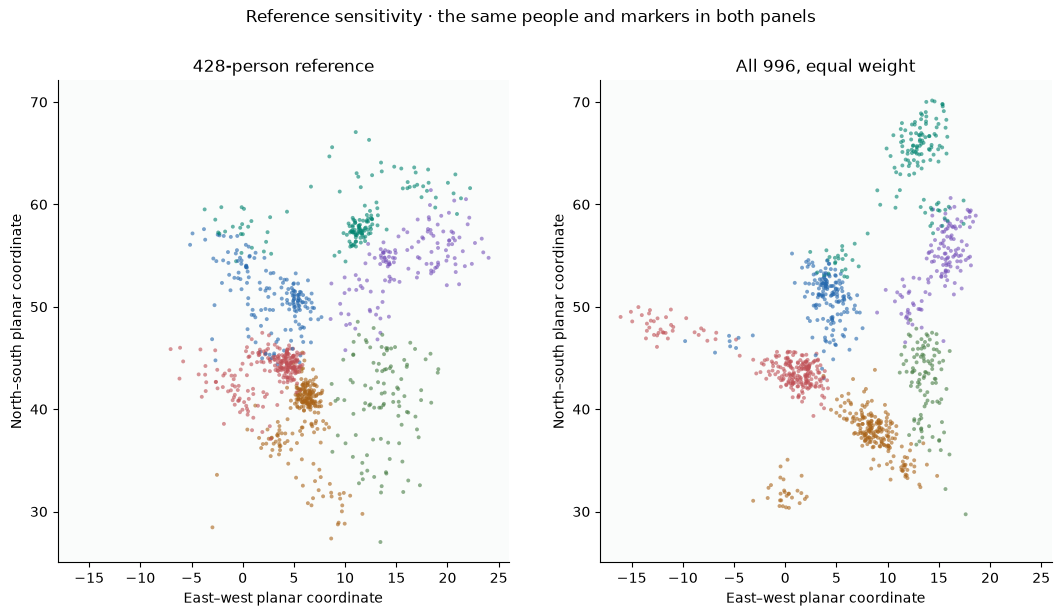

In [10]:
# Refit both allele frequencies and the PCA basis using equal weight for all people.
p_all = np.nanmean(G_pruned, axis=0)/2
denom_all = np.sqrt(2*p_all*(1-p_all))
denom_all[denom_all < 1e-6] = 1
Z_equal = np.nan_to_num((G_pruned-2*p_all)/denom_all, nan=0.0)
model_equal = PCA(n_components=10, random_state=42)
equal_scores = model_equal.fit_transform(Z_equal)
del Z_equal
equal_fit = cohort.copy()
equal_fit[[f"PC{k}" for k in range(1, 11)]] = equal_scores
equal_fit, _ = run_step(pipeline.chunk_8_procrustes_superposition, equal_fit)

sensitivity = pd.DataFrame([
    {"Fit": "428-person reference", **pipeline.descriptive_metrics(results)},
    {"Fit": "All 996, equal weight", **pipeline.descriptive_metrics(equal_fit)}
])

display(sensitivity[["Fit", "r_EastWest_Longitude", "r_NorthSouth_Latitude"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 6))
all_xy = np.vstack([aligned, equal_fit[["RotEW", "RotNS"]].to_numpy()])
lo, hi = all_xy.min(0)-2, all_xy.max(0)+2

for ax, frame, label in zip(axes, [results, equal_fit], sensitivity.Fit):
    ax.scatter(frame.RotEW, frame.RotNS, s=8, c=colors_for(frame), alpha=.6, linewidths=0)
    ax.set_aspect("equal"); ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
    ax.set(title=label, xlabel="East–west planar coordinate", ylabel="North–south planar coordinate")

fig.suptitle("Reference sensitivity · the same people and markers in both panels")
fig.tight_layout(rect=(0, 0, 1, .94))

save_figure(fig, "03_reference_sensitivity.png")

## 7. Exploratory geographic prediction


These exploratory experiments used an earlier **634-person cohort** and its preprocessing. They address geographic prediction rather than shape-preserving PCA. The linear fits are reconstructed below from saved, rounded component scores; neural-network, top-50 and loss-function results are loaded from archived reports, **not retrained here or represented as 996-person results**.

In [11]:
ARCHIVE = research / "data/historical_634"
history_files = {name: ARCHIVE/name for name in [
    "top5_pc_regression_summary.csv", "mlp_loo_globe_experiment.csv",
    "top50_mae_experiment.csv", "mlp_mae_by_pcs.csv", "loss_functions_comparison.csv"]}
history = {name: pd.read_csv(path) for name, path in history_files.items()}
historical_hashes = {str(path.relative_to(project)): digest(path) for path in history_files.values()}
# Match the saved component scores to locality metadata by sample ID.
lab = pd.DataFrame(read_js_data(project/"research/data/historical_634/lab_5pc_data.js")["samples"])
archived_metadata = pd.read_csv(ARCHIVE/"human_origins_pca_results.csv")
assert lab.id.is_unique and archived_metadata.sample_id.is_unique
assert set(lab.id) == set(archived_metadata.sample_id) and len(lab) == 634
archived_metadata = archived_metadata.set_index("sample_id").loc[lab.id]
np.testing.assert_allclose(archived_metadata[["longitude", "latitude"]], lab[["lon", "lat"]])
X_legacy = np.array(lab.unw_pcs.tolist())
Y_legacy = lab[["lon", "lat"]].to_numpy()
legacy_colors = [region_colors[r] for r in lab.region]
legacy_factor = np.cos(np.radians(archived_metadata.groupby("population").latitude.mean().mean()))
print("Five archived experiment reports loaded; sample IDs and locality joins verified.")

Five archived experiment reports loaded; sample IDs and locality joins verified.


### 7.1 More components in a linear model

For the first $k$ PCs, build a design matrix $D=[\mathbf{1},P_{1:k}]$ and fit $\hat\beta=\arg\min_\beta\|D\beta-Y\|_F^2$ to longitude/latitude targets. This is an unconstrained supervised mapping, unlike the similarity transform. The following 1–5-PC fits evaluate the same people used for training; their $R^2$ and kilometre errors describe fit, not prediction.

Saved scores are rounded. Agreement with the archived full-precision training $R^2$ is checked numerically. “Exact mapping” by plotting locality columns directly is simply the geographic reference, not genetic inference.

,PCs,training_R2_longitude,training_R2_latitude,training_mean_km,training_median_km
0,1,0.255,0.712,865.366,812.275
1,2,0.661,0.744,579.734,468.406
2,3,0.818,0.775,490.020,445.392
3,4,0.822,0.796,481.612,452.519
4,5,0.824,0.802,477.221,446.620


,pc_name,delta_r2_lon_pct,delta_r2_lat_pct,cumul_r2_lon_pct,cumul_r2_lat_pct
0,PC1,25.463,71.158,25.463,71.158
1,PC2,40.608,3.288,66.071,74.446
2,PC3,15.708,3.073,81.779,77.519
3,PC4,0.430,2.123,82.209,79.642
4,PC5,0.200,0.510,82.409,80.152


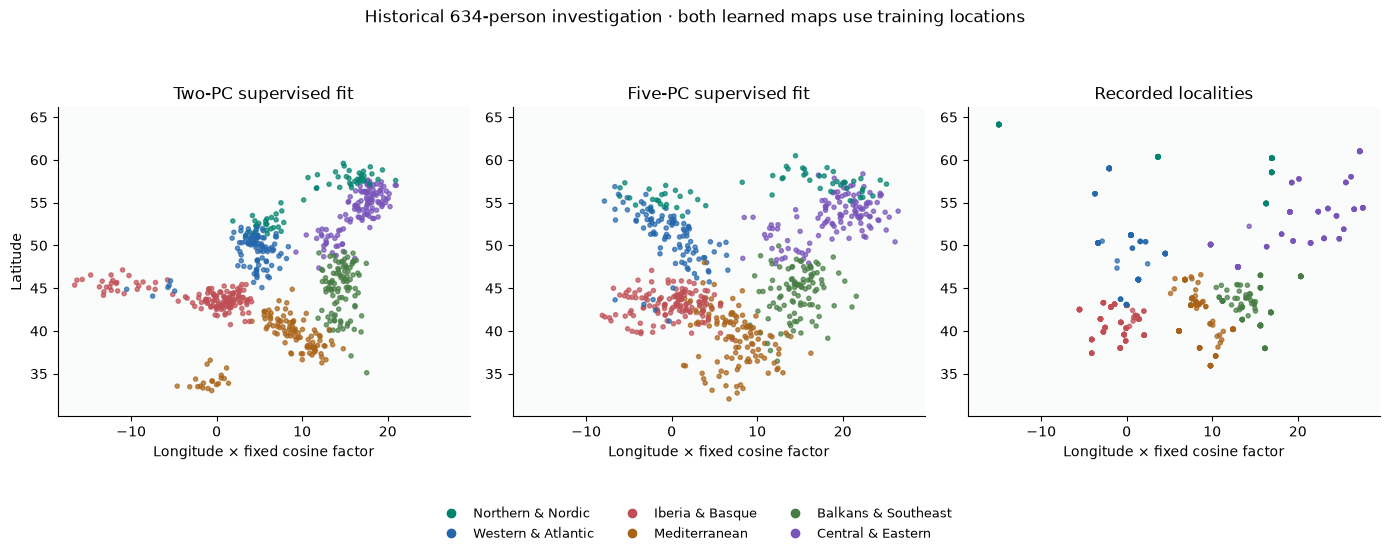

In [12]:
ols_rows, ols_predictions = [], {}
for k in range(1, 6):
    design = np.column_stack([np.ones(len(lab)), X_legacy[:, :k]])
    coefficients = np.linalg.lstsq(design, Y_legacy, rcond=None)[0]
    fitted = design @ coefficients
    ols_predictions[k] = fitted
    r2 = 1-((Y_legacy-fitted)**2).sum(0)/((Y_legacy-Y_legacy.mean(0))**2).sum(0)
    km = haversine_km(*fitted.T, *Y_legacy.T)
    ols_rows.append({"PCs": k, "training_R2_longitude": r2[0], "training_R2_latitude": r2[1],
                     "training_mean_km": km.mean(), "training_median_km": np.median(km)})
ols_reconstruction = pd.DataFrame(ols_rows)
display(ols_reconstruction.round(3))
full_precision = history["top5_pc_regression_summary.csv"]
display(full_precision.loc[(full_precision["mode"] == "Unweighted_All634") & (full_precision.pc_index <= 5),
        ["pc_name", "delta_r2_lon_pct", "delta_r2_lat_pct", "cumul_r2_lon_pct", "cumul_r2_lat_pct"]].round(3))
# The rounded-score reconstruction should recover the reported training fit.
expected = full_precision.loc[(full_precision["mode"] == "Unweighted_All634") & (full_precision.pc_index <= 5)]
np.testing.assert_allclose(ols_reconstruction[["training_R2_longitude", "training_R2_latitude"]],
    expected[["cumul_r2_lon_pct", "cumul_r2_lat_pct"]].to_numpy()/100, atol=2e-5)
fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))
fit_clouds = np.vstack([ols_predictions[2], ols_predictions[5], Y_legacy])*[legacy_factor, 1]
fit_low, fit_high = fit_clouds.min(0)-2, fit_clouds.max(0)+2
for ax, xy, title in zip(axes, [ols_predictions[2], ols_predictions[5], Y_legacy],
                        ["Two-PC supervised fit", "Five-PC supervised fit", "Recorded localities"]):
    ax.scatter(xy[:, 0]*legacy_factor, xy[:, 1], s=9, c=legacy_colors, alpha=.7)
    ax.set_aspect("equal", adjustable="box"); ax.set_title(title)
    ax.set_xlabel("Longitude × fixed cosine factor")
    ax.set_xlim(fit_low[0], fit_high[0]); ax.set_ylim(fit_low[1], fit_high[1])
axes[0].set_ylabel("Latitude")
fig.legend(handles=region_handles, loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.suptitle("Historical 634-person investigation · both learned maps use training locations")
fig.tight_layout(rect=(0, .1, 1, 1))
save_figure(fig, "05_supervised_maps.png")

### 7.2 Linear and neural mapping with held-out targets


The five-PC spherical-output comparison reports mean locality errors of approximately **475 km (linear)** and **401 km (MLP)** when one person is held out; holding out a whole regional group raises these to **538 km** and **457 km**. The mapping models standardized inputs and targets within each training fold, but the PCs were fitted beforehand. These are mapping-stage comparisons conditional on that representation, not fully held-out genotype-to-location pipelines. [Implementation](pipeline/run_mlp_loo_experiment.py).

,PCs,Model,Held out,mean_km_err,median_km_err
1,2,Linear,One person,550.0,485.0
3,2,Neural network,One person,430.4,385.2
4,2,Linear,Regional group,594.4,506.7
5,2,Neural network,Regional group,482.1,424.3
7,5,Linear,One person,474.6,450.4
9,5,Neural network,One person,401.1,357.8
10,5,Linear,Regional group,538.2,477.2
11,5,Neural network,Regional group,457.1,413.1


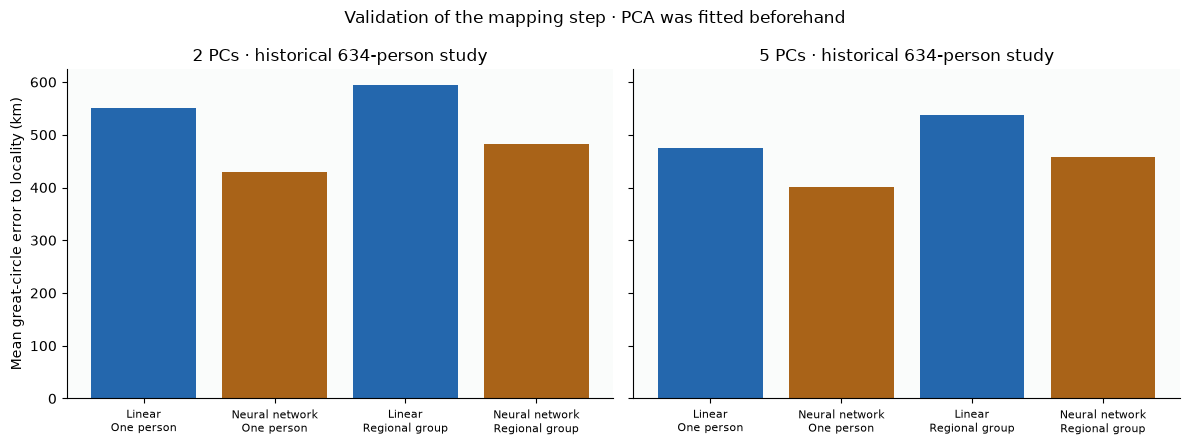

In [13]:
mlp = history["mlp_loo_globe_experiment.csv"].copy()
selected = mlp[mlp.model.str.startswith("Unweighted_PCA_Top") &
               (mlp.model.str.contains("LOO (3D Sphere XYZ)", regex=False) |
                mlp.model.str.contains("LOPO-52", regex=False))].copy()
selected["PCs"] = selected.model.str.extract(r"Top(\d+)PCs").astype(int)
selected["Model"] = np.where(selected.model.str.contains("MLP"), "Neural network", "Linear")
selected["Held out"] = np.where(selected.model.str.contains("LOPO"), "Regional group", "One person")
display(selected[["PCs", "Model", "Held out", "mean_km_err", "median_km_err"]].round(1))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, k in zip(axes, [2, 5]):
    rows = selected[selected.PCs == k]
    labels = rows.Model + "\n" + rows["Held out"]
    ax.bar(range(len(rows)), rows.mean_km_err, color=["#2467ad" if m == "Linear" else "#a96318" for m in rows.Model])
    ax.set_xticks(range(len(rows)), labels, fontsize=8)
    ax.set_title(f"{k} PCs · historical 634-person study")
axes[0].set_ylabel("Mean great-circle error to locality (km)")
fig.suptitle("Validation of the mapping step · PCA was fitted beforehand")
fig.tight_layout()
save_figure(fig, "06_mapping_holdouts.png")

### 7.3 The 2–50-PC experiments


The sweep uses 2, 5, 10, 15, 25 and 50 PCs. Direct fits use 28 hidden units; the 10-fold comparison uses 24 and varies regularization with component count. Training mean error falls from **362 to 192 km**, whereas the mapping-fold error is **353 km at five PCs** and **416 km at fifty**. The separate top-50 suite reports **138 km training** versus **425 km mapping-fold error** for its neural network, under different settings.

These runs do not isolate PC count as the only changing factor. PCA is precomputed in both; the top-50 suite also standardizes globally before its split, while the sweep standardizes within mapping training folds. Both optimize smoothed 3D residuals and report great-circle distances afterwards. [Sweep source](pipeline/run_mlp_mae_by_pcs.py); [top-50 source](pipeline/run_top50_mae_experiment.py).

,Model,mae_km,median_km
0,Linear · 2 PCs · mapping folds,535.6,434.9
1,Linear · 5 PCs · mapping folds,452.8,395.2
2,Linear · 15 PCs · mapping folds,445.0,401.9
3,Linear · 50 PCs · mapping folds,457.7,404.8
4,Linear · 50 PCs · training,412.1,357.4
5,MLP · 50 PCs · training,138.3,64.4
6,MLP · 50 PCs · mapping folds,424.6,373.0


mode,Training fit,10-fold mapping comparison
k_pcs,,
2,362.5,373.1
5,341.8,353.2
10,331.8,372.2
15,325.2,373.3
25,294.4,409.0
50,192.2,415.9


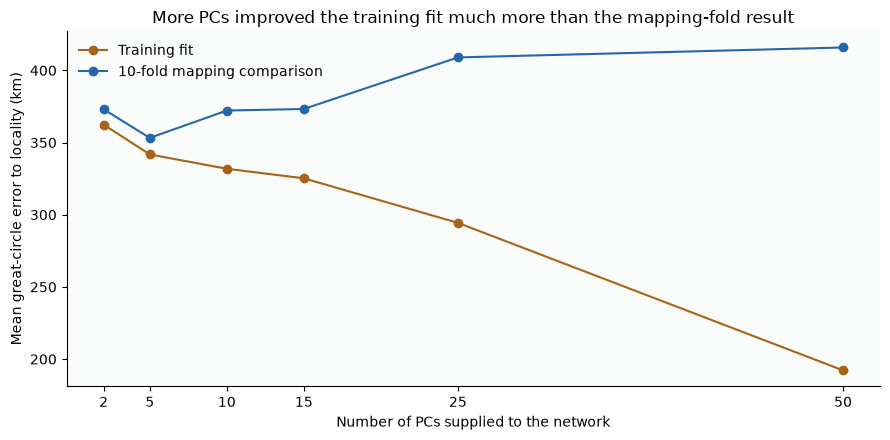

In [14]:
top50 = history["top50_mae_experiment.csv"].copy()
top50["Model"] = ["Linear · 2 PCs · mapping folds", "Linear · 5 PCs · mapping folds",
                      "Linear · 15 PCs · mapping folds", "Linear · 50 PCs · mapping folds",
                      "Linear · 50 PCs · training", "MLP · 50 PCs · training", "MLP · 50 PCs · mapping folds"]
display(top50[["Model", "mae_km", "median_km"]].round(1))
sweep = history["mlp_mae_by_pcs.csv"].copy()
comparison = sweep.pivot(index="k_pcs", columns="mode", values="mae_km")
comparison = comparison.rename(columns={"Direct_Supervised_MAE": "Training fit", "Out_of_Sample_CV_MAE": "10-fold mapping comparison"})
display(comparison.round(1))
fig, ax = plt.subplots(figsize=(9, 4.5))
for label, color in [("Training fit", "#a96318"), ("10-fold mapping comparison", "#2467ad")]:
    ax.plot(comparison.index, comparison[label], "o-", label=label, color=color)
ax.set_xticks(comparison.index)
ax.set_xlabel("Number of PCs supplied to the network")
ax.set_ylabel("Mean great-circle error to locality (km)")
ax.set_title("More PCs improved the training fit much more than the mapping-fold result")
ax.legend(frameon=False)
fig.tight_layout()
save_figure(fig, "07_component_sweep.png")

### 7.4 Loss and geographic dispersion


The six variants compare squared error, smoothed 3D residuals, Huber-like and Cauchy-like residual weighting, and a target-spread term. Labels below describe the implementation. The spread term uses output standard deviations; it never reads a coastline polygon.

These are exploratory results: PCA, global input/target standardization and the target-spread statistic were computed before the mapping folds. Custom gradient scaling has not been independently validated. Thus these values do not establish clean predictive superiority for a standard named loss. The spread variant gives approximately **365 km mean error**, versus **343 km** for the smoothed-3D-residual variant, despite better dispersion matching. [Implemented experiments](pipeline/compare_loss_functions.py).

,Implemented variant,mean_km,median_km,lon_spread_pct,lat_spread_pct
0,Planar squared error,361.3,317.1,92.5,93.0
1,Standardized XYZ squared error,355.1,317.1,91.9,94.5
2,Smoothed 3D residual,343.0,301.3,88.2,92.9
3,Huber-like residual weighting,351.0,306.9,87.6,91.7
4,Cauchy-like residual weighting,362.0,319.3,84.6,89.5
5,Huber-like plus target spread,364.7,323.2,94.4,95.8


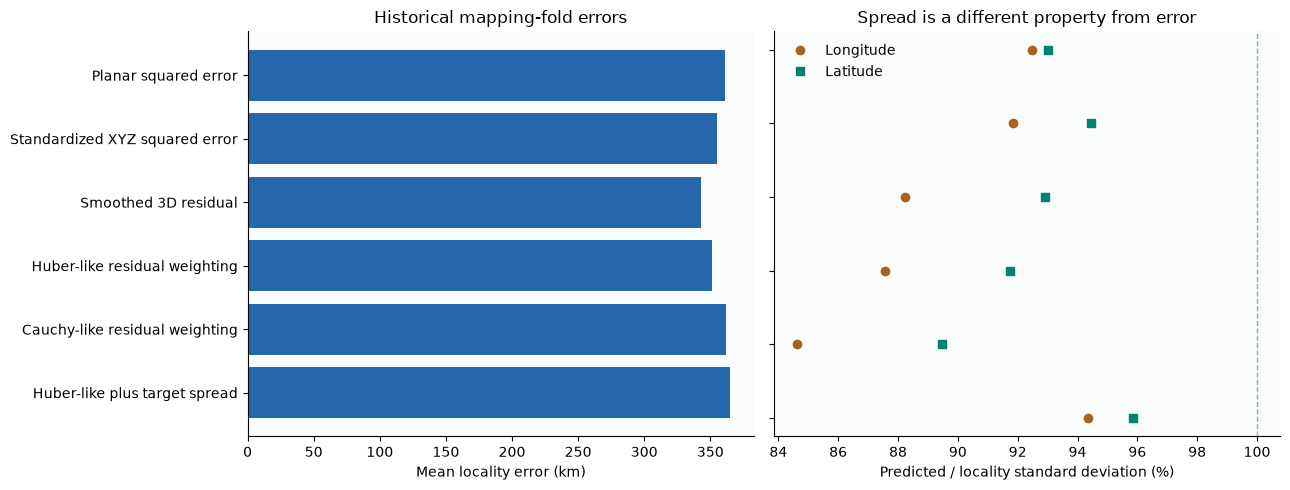

In [15]:
losses = history["loss_functions_comparison.csv"].copy()
loss_labels = ["Planar squared error", "Standardized XYZ squared error", "Smoothed 3D residual",
               "Huber-like residual weighting", "Cauchy-like residual weighting", "Huber-like plus target spread"]
assert len(losses) == len(loss_labels)
losses["Implemented variant"] = loss_labels
display(losses[["Implemented variant", "mean_km", "median_km", "lon_spread_pct", "lat_spread_pct"]].round(1))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
y = np.arange(len(losses))
axes[0].barh(y, losses.mean_km, color="#2467ad")
axes[0].set_yticks(y, loss_labels); axes[0].invert_yaxis()
axes[0].set_xlabel("Mean locality error (km)"); axes[0].set_title("Historical mapping-fold errors")
axes[1].plot(losses.lon_spread_pct, y, "o", label="Longitude", color="#a96318")
axes[1].plot(losses.lat_spread_pct, y, "s", label="Latitude", color="#00836f")
axes[1].axvline(100, color="#9aa9ad", lw=1, ls="--")
axes[1].set_yticks(y, []); axes[1].invert_yaxis(); axes[1].set_xlabel("Predicted / locality standard deviation (%)")
axes[1].set_title("Spread is a different property from error"); axes[1].legend(frameon=False)
fig.tight_layout()
save_figure(fig, "08_loss_and_dispersion.png")

## 8. Discussion

The leading genetic components show a recognizable regional arrangement without fitting a coastline. Geographic alignment makes that correspondence easier to read while preserving the two-PC shape. Supervised models answer a different question: additional components and nonlinear mappings can improve training fits, but performance depends on the evaluation design and does not establish exact geographic reconstruction.

The final presentation therefore uses the two-PC cloud, one common alignment scale, regional annotations and a locality-coordinate comparison. Regional mismatches remain visible rather than being corrected point by point. This is an adaptation of the phenomenon in Novembre et al., not an exact replication of their POPRES analysis.

Sampling is uneven: Italy and Spain account for about 43% of the cohort and some countries are absent. Locality proxies, inherited exclusions, strict marker ascertainment, platform/source effects, residual LD, relatedness and the fixed reference design limit interpretation. No specific ancestral journeys or individual nationality can be inferred from these figures.

A future predictive study would fit all preprocessing and PCA within training data, use appropriate population/source holdouts, and perform model selection inside the validation design. Historical mapping-fold results do not retrospectively satisfy that design.

## 9. Reproducibility checks and references

Current PC scores and aligned coordinates are compared by sample ID with the final dataset. Working tables, retained marker IDs, source/input hashes, software versions, and the distinction between recomputed and archived results are saved alongside this notebook's figures.

In [16]:
canonical = pd.read_csv(research/"results/stats/human_origins_pca_results.csv").set_index("sample_id")
computed = results.set_index("sample_id").loc[canonical.index]

assert len(computed) == 996 and set(computed.index) == set(canonical.index)
columns = [*[f"PC{k}" for k in range(1, 11)], "RotEW", "RotNS", "rotLon", "rotLat"]
np.testing.assert_allclose(computed[columns], canonical[columns], rtol=2e-5, atol=2e-5)

for rel, expected_hash in {**protected_hashes, **historical_hashes}.items():
    assert digest(project/rel) == expected_hash, f"Protected file changed: {rel}"

results.to_csv(pipeline.STATS/"human_origins_pca_results.csv", index=False)
summary.to_csv(pipeline.STATS/"descriptive_correlations.csv", index=False)
sensitivity.to_csv(pipeline.STATS/"reference_sensitivity.csv", index=False)

ols_reconstruction.to_csv(pipeline.STATS/"historical_ols_reconstruction.csv", index=False)
(pipeline.STATS/"alignment_transform.json").write_text(json.dumps(alignment, indent=2)+"\n")
run_step(pipeline.write_run_manifest, cohort, retained_snps, metrics)

checks = {"Current individuals": len(computed), "Retained markers": G_pruned.shape[1],
          "Current scores and alignment agree with final data": "PASS",
          "Common scale preserves planar shape": "PASS",
          "App and canonical outputs unchanged": "PASS",
          "Archived reports unchanged": "PASS"}

display(pd.Series(checks, name="Result").to_frame())

(pipeline.STATS/"notebook_provenance.json").write_text(json.dumps({
    "notebook": "genes_mirror_geography_replication.ipynb", "current_cohort": 996,
    "historical_model_cohort": 634,
    "recomputed": ["genotype QC", "reference PCA", "similarity alignment",
                   "equal-weight sensitivity", "rounded-score historical OLS"],
    "loaded_model_reports": list(history_files),
    "historical_report_sha256": historical_hashes,
    "checks": checks
}, indent=2)+"\n")

Out[16]: 1460


,Result
Current individuals,996
Retained markers,46213
Current scores and alignment agree with final data,PASS
Common scale preserves planar shape,PASS
App and canonical outputs unchanged,PASS
Archived reports unchanged,PASS


- Novembre et al. (2008), *Genes mirror geography within Europe*, Nature 456:98–101, particularly Figure 1 and Methods. This project uses AADR, not the paper's POPRES dataset.
- Patterson, Price & Reich (2006), [Population Structure and Eigenanalysis](https://journals.plos.org/plosgenetics/article?id=10.1371/journal.pgen.0020190), for population-genetic PCA.
- [scikit-learn PCA documentation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), for the estimator's centering, component and variance conventions; [preprocessing and leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html), for validation design.
- [TGENO format specification](https://github.com/DReichLab/AdmixTools/blob/master/transpose_info/transpose_format.txt).
- Local inputs and software versions are recorded in this notebook's `run_manifest.json`. Archived experiment scripts are linked at the relevant analyses.